# Notebook 1 — Flatness Profile EDA

Exploratory Data Analysis of synthetic cold-rolling mill flatness profiles.

## What is a flatness profile?

After cold-rolling, each steel coil is measured by a **flatness gauge** that records
the relative elongation difference across the strip width.  The result is a 2D array:

```
profile[w, l] = flatness in I-units at width position w, length position l
```

- **Width** axis (rows): 150 points across the 1.5m-wide strip
- **Length** axis (cols): 2000 points along the coil length (up to several km)
- **1 I-unit** = 10⁻⁵ relative elongation difference
- **Ideal coil**: all values near 0; **defective coil**: peaks at ±20 to ±50 I-units

## Pattern classes (10 classes)

| Class | Physics |
|-------|---------|
| `center_wave` | Insufficient center tension → center elongates more than edges |
| `edge_wave` | Edge elongation from work-roll contact → edge buckling |
| `symmetric_bow` | Thermal gradient → parabolic curvature across width |
| `quarter_buckle` | Asymmetric roll force → off-center buckling at 25% or 75% width |
| `flat` | Correctly rolled reference coil |
| `random_noise` | Mixed/unclassifiable defects |
| `longitudinal_bow` | Parabolic flatness varying along coil length (thermal/tension gradient during hot rolling) |
| `complex_wave` | Linear mix of center_wave + edge_wave (hardest class, sits between parents) |
| `herringbone_wave` | Diagonal cross-hatch pattern from roll misalignment |
| `periodic_mark` | Repeating periodic marks from roll surface defects |

## Features (125-dimensional)

| Group | Features | Description |
|-------|----------|-------------|
| A (0-29)   | 30 | Zonal statistics (mean, std, skewness, kurtosis per zone) |
| B (30-79)  | 50 | Cross-width snapshots at 5 positions |
| C (80-94)  | 15 | Spectral features (FFT) |
| D (95-104) | 10 | Temporal evolution (Saas et al. 2017: autocorr, DTW, PAA) |
| E (105-124)| 20 | ROCKET random convolutional kernels (Dempster et al. 2020) |

In [1]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

ROOT = Path("..").resolve().parent   # repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "flatness_clustering" / "data" / "synthetic_profiles"

if not DATA_DIR.exists():
    print("Generating synthetic data...")
    os.system(f'python "{ROOT / "flatness_clustering" / "data" / "generate_flatness_data.py"}"')

from flatness_clustering.data.flatness_dataset import FlatnessDataset

dataset = FlatnessDataset(str(DATA_DIR))
print(dataset)

# 10 classes (added herringbone_wave and periodic_mark in latest update)
CLASS_NAMES  = ["center_wave", "edge_wave", "symmetric_bow",
                "quarter_buckle", "flat", "random_noise",
                "longitudinal_bow", "complex_wave",
                "herringbone_wave", "periodic_mark"]
CLASS_COLORS = ["#E91E63", "#2196F3", "#FF9800", "#4CAF50",
                "#9C27B0", "#607D8B", "#FF5722", "#00BCD4",
                "#795548", "#3F51B5"]

print(f"\nDataset has {len(CLASS_NAMES)} pattern classes")

FlatnessDataset(1200 coils, root='flatness_clustering\data\synthetic_profiles', patterns={'center_wave': 120, 'edge_wave': 120, 'symmetric_bow': 120, 'quarter_buckle': 120, 'flat': 120, 'random_noise': 120, 'longitudinal_bow': 120, 'complex_wave': 120, 'herringbone_wave': 120, 'periodic_mark': 120})

Dataset has 10 pattern classes


## 1. Heatmap Gallery — One Profile per Class

Each plot shows the full (150 × 2000) flatness profile with:
- **Red = positive I-units** (elongation excess)
- **Blue = negative I-units** (elongation deficit)
- **White = zero** (flat)

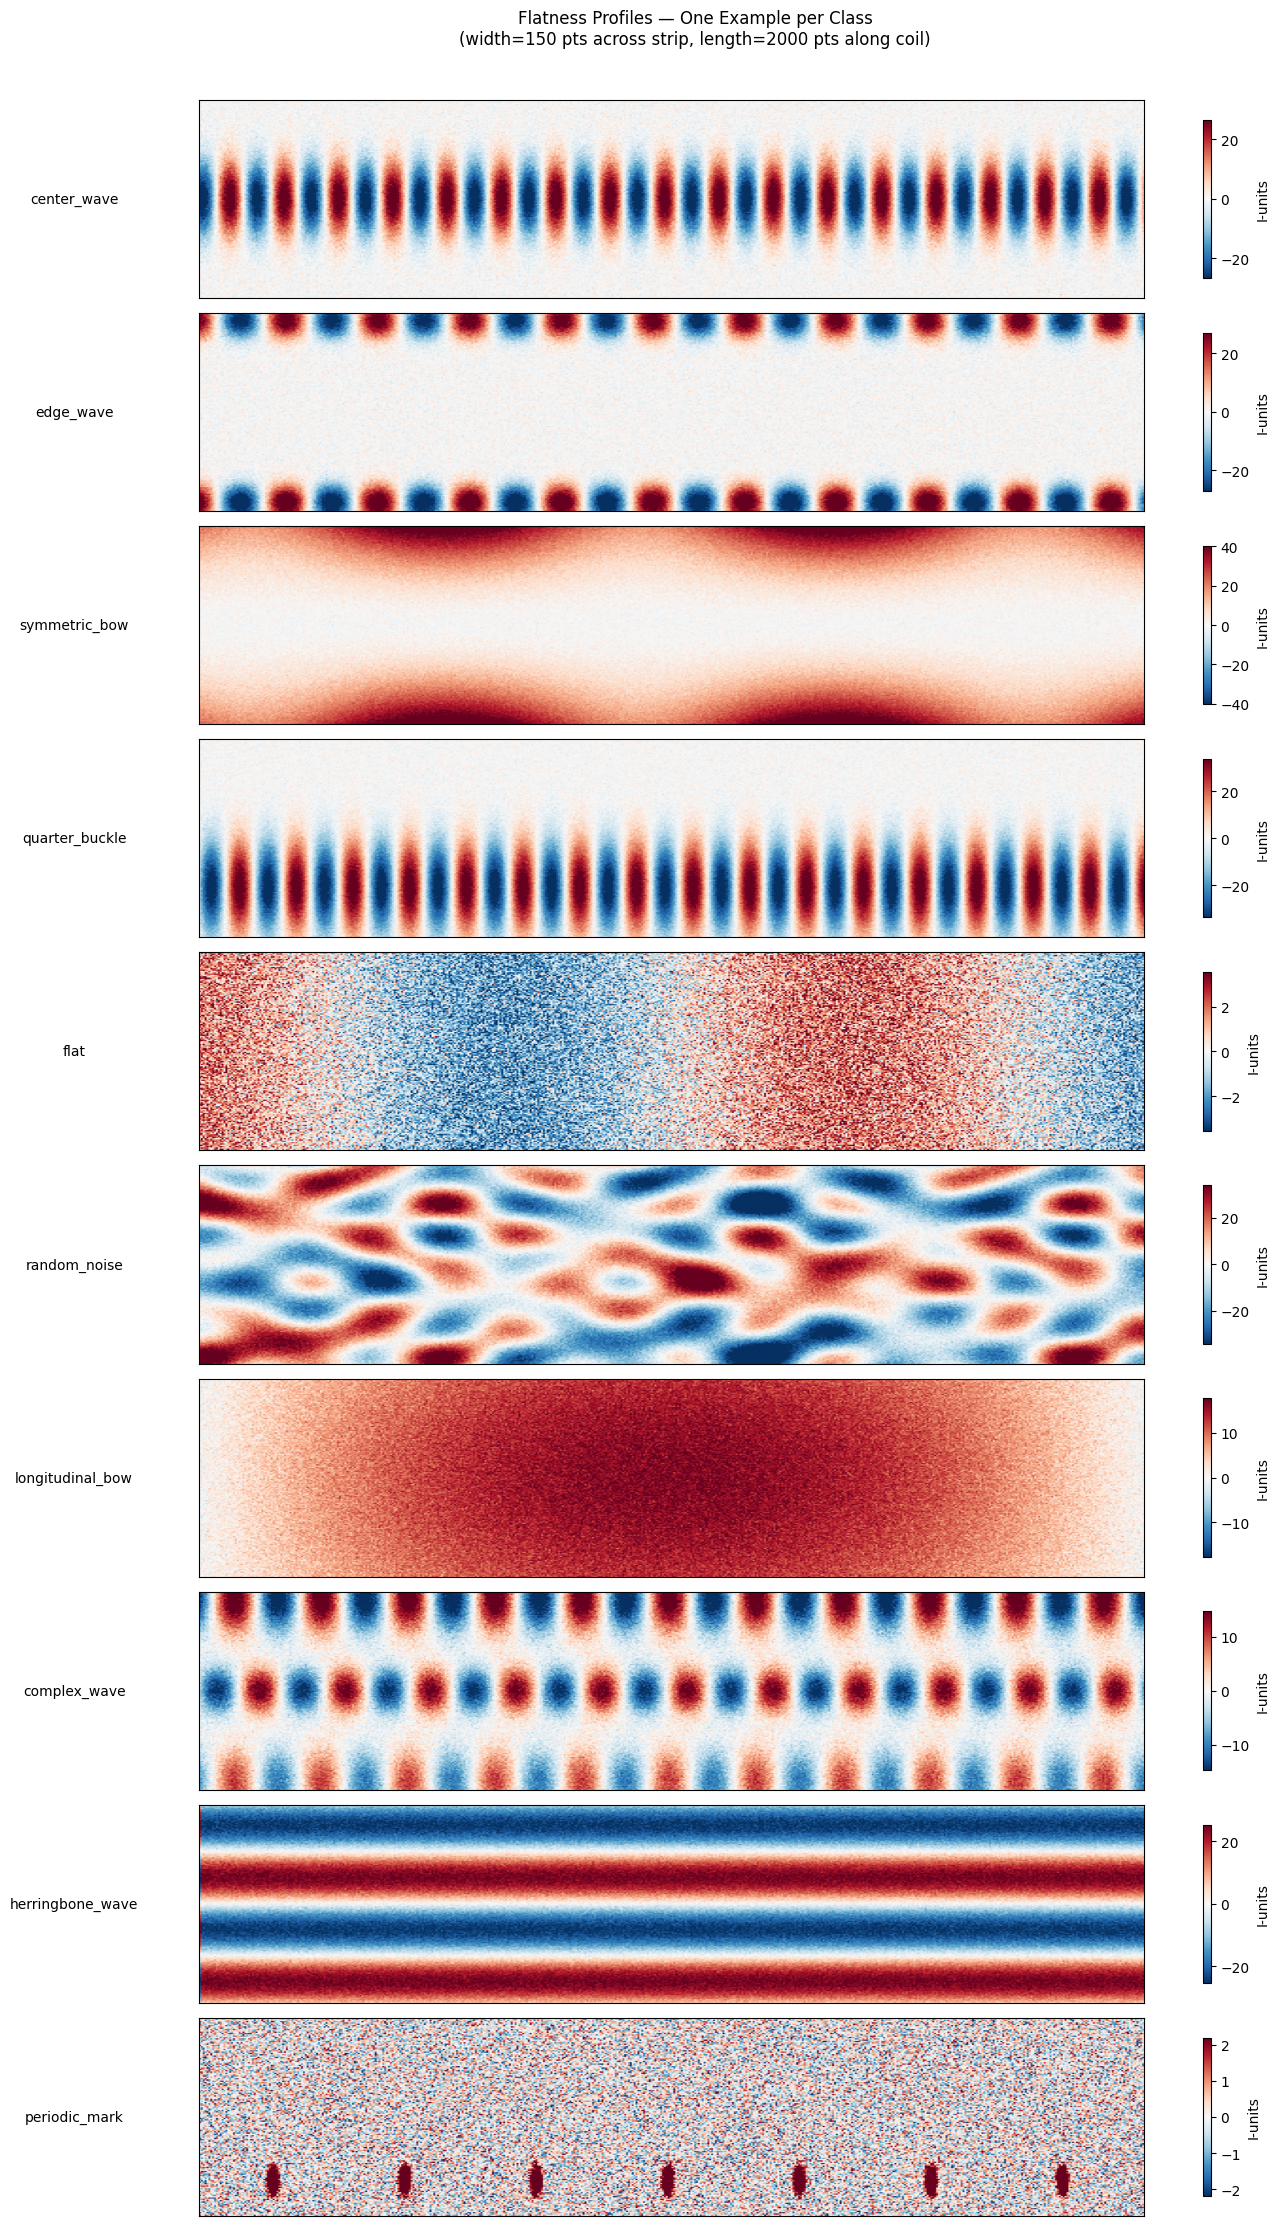

In [2]:
fig, axes = plt.subplots(len(CLASS_NAMES), 1, figsize=(14, len(CLASS_NAMES) * 2.2))

for ax, cls_name in zip(axes, CLASS_NAMES):
    # Load first profile of this class
    cls_ds = dataset.filter_by_pattern(cls_name)
    profile = cls_ds[0]["profile"]   # (W, L)

    # Display downsampled for speed (every 2nd row and 5th col)
    display = profile[::1, ::4]
    vmax = max(abs(float(np.percentile(profile, 98))),
               abs(float(np.percentile(profile, 2))))

    im = ax.imshow(display, aspect="auto", cmap="RdBu_r",
                   vmin=-vmax, vmax=vmax)
    ax.set_ylabel(cls_name, fontsize=10, rotation=0, labelpad=90, va="center")
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, label="I-units", shrink=0.8)

plt.suptitle("Flatness Profiles — One Example per Class\n"
             "(width=150 pts across strip, length=2000 pts along coil)",
             fontsize=12, y=1.01)
plt.tight_layout()
os.makedirs(ROOT / "flatness_clustering" / "outputs" / "plots", exist_ok=True)
plt.savefig(ROOT / "flatness_clustering" / "outputs" / "plots" / "eda_heatmap_gallery.png",
            dpi=120, bbox_inches="tight")
plt.show()

## 2. Cross-Width Profiles at 5 Positions Along the Coil

This shows how the flatness *shape* evolves along the coil length.
Each subplot is a cross-section at 10%, 30%, 50%, 70%, 90% of coil length.

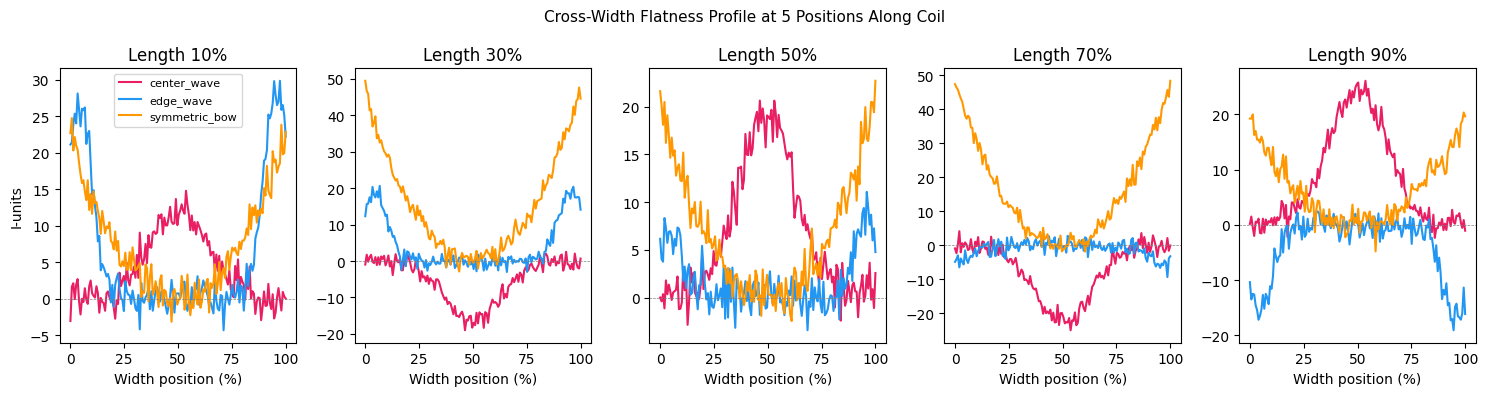

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4), sharey=False)
positions_pct = [0.10, 0.30, 0.50, 0.70, 0.90]

# Show center_wave vs edge_wave to highlight the difference
compare_classes = ["center_wave", "edge_wave", "symmetric_bow"]
compare_colors  = ["#E91E63", "#2196F3", "#FF9800"]

profiles_compare = {}
for cls in compare_classes:
    profiles_compare[cls] = dataset.filter_by_pattern(cls)[0]["profile"]

for ax, pos_pct in zip(axes, positions_pct):
    for cls, color in zip(compare_classes, compare_colors):
        profile = profiles_compare[cls]
        l_idx = int(pos_pct * profile.shape[1])
        cross = profile[:, l_idx]
        w_axis = np.linspace(0, 100, len(cross))
        ax.plot(w_axis, cross, color=color, linewidth=1.5, label=cls)

    ax.axhline(0, color="grey", linewidth=0.5, linestyle="--")
    ax.set_title(f"Length {int(pos_pct*100)}%")
    ax.set_xlabel("Width position (%)")
    if pos_pct == 0.10:
        ax.set_ylabel("I-units")
        ax.legend(fontsize=8)

plt.suptitle("Cross-Width Flatness Profile at 5 Positions Along Coil", fontsize=11)
plt.tight_layout()
plt.savefig(ROOT / "flatness_clustering" / "outputs" / "plots" / "eda_cross_width.png",
            dpi=120)
plt.show()

## 3. Peak-to-Valley Distribution per Class

Peak-to-valley (max - min I-units) is a key quality metric.
Flat coils should have P2V near 0; defective ones can reach 50+ I-units.

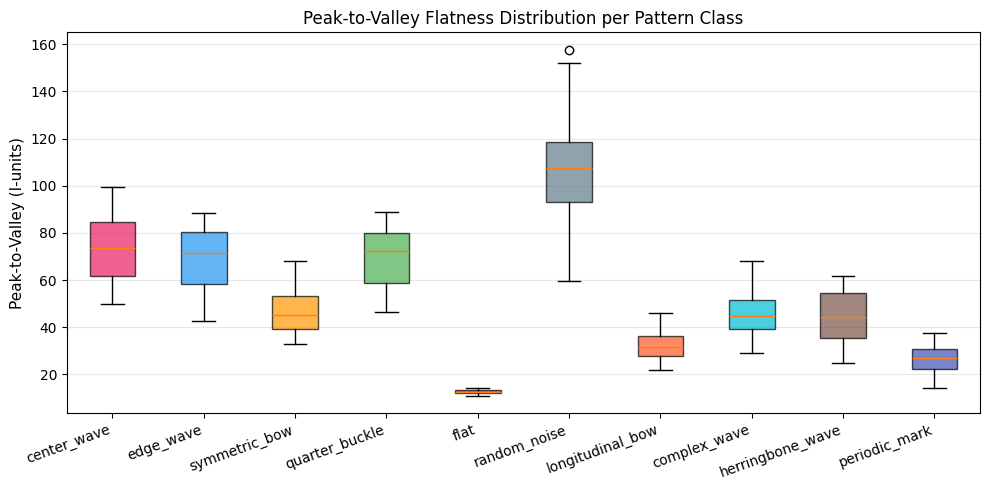


Mean peak-to-valley per class:
pattern
center_wave          73.400002
complex_wave         45.540001
edge_wave            69.070000
flat                 12.630000
herringbone_wave     44.810001
longitudinal_bow     32.340000
periodic_mark        26.790001
quarter_buckle       69.690002
random_noise        105.839996
symmetric_bow        46.810001


In [4]:
# Compute P2V for all coils
profiles, metadata = dataset.load_all_profiles()
p2v = profiles.max(axis=(1, 2)) - profiles.min(axis=(1, 2))
metadata["peak_to_valley"] = p2v

fig, ax = plt.subplots(figsize=(10, 5))
order = CLASS_NAMES
data_by_class = [metadata[metadata["pattern"] == cls]["peak_to_valley"].values
                 for cls in order]

bp = ax.boxplot(data_by_class, patch_artist=True, notch=False)
for patch, color in zip(bp["boxes"], CLASS_COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_xticklabels(order, rotation=20, ha="right", fontsize=10)
ax.set_ylabel("Peak-to-Valley (I-units)", fontsize=11)
ax.set_title("Peak-to-Valley Flatness Distribution per Pattern Class", fontsize=12)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / "flatness_clustering" / "outputs" / "plots" / "eda_p2v_boxplot.png",
            dpi=120)
plt.show()

print("\nMean peak-to-valley per class:")
print(metadata.groupby("pattern")["peak_to_valley"].mean().round(2).to_string())

## 4. FFT Power Spectrum Comparison

Different defect types have characteristic spatial frequencies.
Center-wave defects oscillate slowly (low frequency), while noise fills all bands.

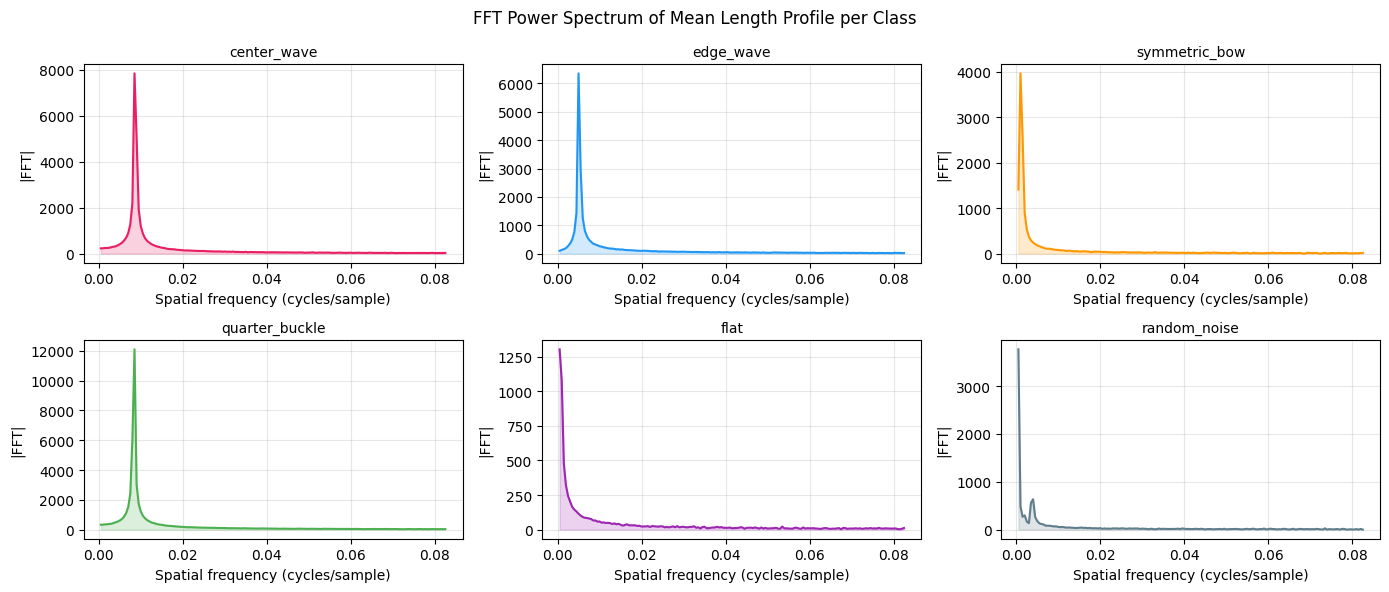

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))

for ax, cls, color in zip(axes.flat, CLASS_NAMES, CLASS_COLORS):
    cls_ds = dataset.filter_by_pattern(cls)
    profile = cls_ds[0]["profile"]   # (W, L)

    # Mean profile along length (one value per width position)
    mean_length = profile.mean(axis=0)   # (L,)
    fft_mag = np.abs(np.fft.rfft(mean_length))
    freqs = np.fft.rfftfreq(len(mean_length))

    # Plot only low-to-mid frequencies
    cutoff = len(freqs) // 6
    ax.plot(freqs[1:cutoff], fft_mag[1:cutoff], color=color, linewidth=1.5)
    ax.fill_between(freqs[1:cutoff], fft_mag[1:cutoff], alpha=0.2, color=color)
    ax.set_title(cls, fontsize=10)
    ax.set_xlabel("Spatial frequency (cycles/sample)")
    ax.set_ylabel("|FFT|")
    ax.grid(alpha=0.3)

plt.suptitle("FFT Power Spectrum of Mean Length Profile per Class", fontsize=12)
plt.tight_layout()
plt.savefig(ROOT / "flatness_clustering" / "outputs" / "plots" / "eda_fft_spectra.png",
            dpi=120)
plt.show()

## 5. Statistical Feature Preview (125-dimensional)

Quick preview of the 125-dim feature vector for one coil per class.

Features are organized in 5 groups:
- **Group A (0–29)**: Zonal statistics — mean, std, skewness, kurtosis per zone
- **Group B (30–79)**: Cross-width snapshots at 5 positions
- **Group C (80–94)**: Spectral features (FFT magnitudes)
- **Group D (95–104)**: Temporal evolution features (Saas et al. 2017)
- **Group E (105–124)**: ROCKET random convolutional kernels (Dempster et al. 2020)

In [6]:
from flatness_clustering.features.statistical_features import (
    extract_statistical_features, feature_names,
)

feat_names = feature_names()
print(f"Total features: {len(feat_names)}  (should be 125)")
print(f"  Group A (zonal stats):          features 0-29   ({feat_names[0]} .. {feat_names[29]})")
print(f"  Group B (cross-width):          features 30-79  ({feat_names[30]} .. {feat_names[79]})")
print(f"  Group C (spectral):             features 80-94  ({feat_names[80]} .. {feat_names[94]})")
print(f"  Group D (temporal evolution):   features 95-104 ({feat_names[95]} .. {feat_names[104]})")
print(f"  Group E (ROCKET kernels):       features 105-124 ({feat_names[105]} .. {feat_names[124]})")

rows = []
for cls in CLASS_NAMES:
    try:
        profile = dataset.filter_by_pattern(cls)[0]["profile"]
        feat = extract_statistical_features(profile)
        rows.append({"pattern": cls, **dict(zip(feat_names[:10], feat[:10]))})
    except (IndexError, KeyError):
        pass  # Skip if class not in dataset yet

preview_df = pd.DataFrame(rows).set_index("pattern")
print("\nFirst 10 features per class:")
print(preview_df.round(3).to_string())

Total features: 125  (should be 125)
  Group A (zonal stats):          features 0-29   (zone_left_edge_mean .. zone_right_edge_kurtosis)
  Group B (cross-width):          features 30-79  (snap000pct_left_mean .. snap100pct_slope)
  Group C (spectral):             features 80-94  (spectral_width_power_dc .. spectral_profile_rms_global)
  Group D (temporal evolution):   features 95-104 (temporal_length_autocorr_lag10 .. temporal_paa_shape_distance)
  Group E (ROCKET kernels):       features 105-124 (rocket_k00_max .. rocket_k09_ppv)

First 10 features per class:
                  zone_left_edge_mean  zone_left_edge_std  zone_left_edge_peak2valley  zone_left_edge_rms  zone_left_edge_skewness  zone_left_edge_kurtosis  zone_left_quarter_mean  zone_left_quarter_std  zone_left_quarter_peak2valley  zone_left_quarter_rms
pattern                                                                                                                                                                         

## Group D Temporal Evolution Features (Saas et al. 2017)

10 new temporal features capture **longitudinal evolution** along the coil length:

| Feature | Formula | Captures |
|---------|---------|----------|
| `length_autocorr_lag{10,50,100}` | $r_{xx}(\tau) = \text{corr}(x[:-\tau], x[\tau:])$ | Periodic patterns |
| `self_similarity_dtw` | DTW(first ⅓, last ⅓) | Longitudinal change |
| `amplitude_trend_slope` | polyfit of window peak-to-valley | Degradation trend |
| `spectral_entropy` | $H = -\sum p_f \log p_f$ | Frequency distribution |
| `wavelet_energy_ratio` | $\sum \Delta x^2 / \sum x^2$ | Edge sharpness |
| `temporal_std_of_std` | std of window stds | Non-stationarity |
| `edge_cross_correlation` | Pearson r (left edge, right edge) | Symmetry evolution |
| `paa_shape_distance` | $\|PAA(\text{first half}) - PAA(\text{second half})\|_2$ | Shape drift |

In [7]:
import numpy as np
import sys, os
sys.path.insert(0, os.path.abspath("../.."))
from flatness_clustering.features.statistical_features import extract_statistical_features, feature_names

np.random.seed(42)
# Compare Group D features for two different synthetic profiles
profile_flat = np.random.randn(150, 2000).astype(np.float32) * 0.1      # nearly flat
profile_wavy = (np.sin(np.linspace(0, 8*np.pi, 2000)) * 5.0 +
                np.random.randn(150, 2000) * 0.5).astype(np.float32)    # wavy

f_flat = extract_statistical_features(profile_flat)
f_wavy = extract_statistical_features(profile_wavy)
names  = feature_names()

# Group D: features 95–104 (temporal evolution)
group_d_names = [n for n in names if n.startswith("temporal_")]
group_d_flat  = f_flat[95:105]
group_d_wavy  = f_wavy[95:105]

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

x = np.arange(len(group_d_names))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - width/2, group_d_flat, width, label="Flat profile", color="#2196F3", alpha=0.8)
ax.bar(x + width/2, group_d_wavy, width, label="Wavy profile", color="#FF5722", alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels([n.replace("temporal_", "") for n in group_d_names],
                   rotation=40, ha="right", fontsize=9)
ax.set_title("Group D Temporal Features: Flat vs Wavy Profile\n(Saas et al. 2017)")
ax.legend()
plt.tight_layout()
plt.savefig("group_d_comparison.png", dpi=120)
print(f"Total feature dim: {len(names)}  (should be 125)")
print("Saved: group_d_comparison.png")

Total feature dim: 125  (should be 125)
Saved: group_d_comparison.png
